# Zajęcia 2 — Sieci rekurencyjne: budowa i uczenie

**Cel:** zaimplementować prosty RNN w PyTorch i nauczyć go przewidywać kolejną
próbkę szeregu czasowego (sygnał sinusoidalny z szumem). Zbadać krzywą uczenia
oraz wpływ typu komórki (RNN/LSTM/GRU), liczby jednostek i długości okna.

Uruchamiaj komórki po kolei (Shift+Enter).

*Prowadzący: dr Tomasz Cieplak / mgr inż. Patryk Marek, Rok akademicki: 2026/27*

## 1. Instalacja i import

In [ ]:
!pip -q install torch numpy matplotlib

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0); np.random.seed(0)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Urządzenie:', DEVICE)

Urządzenie: cpu


## 2. Dane: szereg czasowy

Generujemy sygnał sinusoidalny z niewielkim szumem — prosty, powtarzalny szereg,
na którym łatwo zobaczyć, czy sieć nauczyła się struktury.

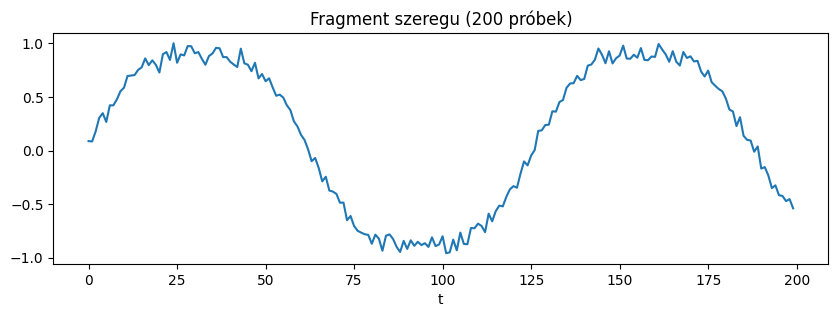

In [ ]:
def generuj_szereg(n=2000):
    t = np.linspace(0, 100, n)
    y = np.sin(t) + 0.1*np.sin(3*t) + 0.05*np.random.randn(n)
    return y.astype(np.float32)

seria = generuj_szereg()
plt.figure(figsize=(10,3))
plt.plot(seria[:200])
plt.title('Fragment szeregu (200 próbek)'); plt.xlabel('t'); plt.show()

## 3. Okna wejście–cel

Z ciągu tworzymy przykłady uczące: **okno** kolejnych próbek jako wejście,
a następna próbka jako cel (zadanie *sequence-to-vector*).

In [ ]:
def zrob_okna(seria, okno=30):
    X, Y = [], []
    for i in range(len(seria)-okno):
        X.append(seria[i:i+okno]); Y.append(seria[i+okno])
    X = np.array(X, dtype=np.float32)[..., None]  # [N, okno, 1]
    Y = np.array(Y, dtype=np.float32)[:, None]     # [N, 1]
    return X, Y

OKNO = 30
X, Y = zrob_okna(seria, OKNO)

# Podział chronologiczny (bez tasowania — to szereg czasowy!)
n_tr = int(0.8*len(X))
Xtr = torch.tensor(X[:n_tr]).to(DEVICE); Ytr = torch.tensor(Y[:n_tr]).to(DEVICE)
Xte = torch.tensor(X[n_tr:]).to(DEVICE); Yte = torch.tensor(Y[n_tr:]).to(DEVICE)
print('Trening:', Xtr.shape, ' Test:', Xte.shape)

Trening: torch.Size([1576, 30, 1])  Test: torch.Size([394, 30, 1])


In [ ]:
mse_heurystyki = ((Yte - Xte[:, -1])**2).mean().item()
print(f'MSE prostej heurystyki (prognoza = ostatnia próbka): {mse_heurystyki:.4f}')

MSE prostej heurystyki (prognoza = ostatnia próbka): 0.0063


## 4. Model RNN

Jedna warstwa rekurencyjna + warstwa liniowa na ostatnim stanie ukrytym.
Parametr `typ` przełącza SimpleRNN / LSTM / GRU.

In [ ]:
class ModelRNN(nn.Module):
    def __init__(self, hidden=32, typ='RNN'):
        super().__init__()
        rnn = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[typ]
        self.rnn = rnn(input_size=1, hidden_size=hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])   # ostatni krok -> predykcja

## 5. Pętla uczenia

In [ ]:
def trenuj(model, Xtr, Ytr, Xte, Yte, epoki=30, lr=1e-2, batch=64):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    strata = nn.MSELoss()
    hist = []
    hist_tr = []
    n = len(Xtr)
    for ep in range(epoki):
        model.train(); perm = torch.randperm(n)
        for i in range(0, n, batch):
            idx = perm[i:i+batch]
            opt.zero_grad()
            loss = strata(model(Xtr[idx]), Ytr[idx])
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)  # anti-eksplozja
            opt.step()
        model.eval()
        with torch.no_grad():
            hist.append(strata(model(Xte), Yte).item())
            hist_tr.append(strata(model(Xtr), Ytr).item())
    return hist, hist_tr

model = ModelRNN(hidden=32, typ='RNN')
hist, hist_tr = trenuj(model, Xtr, Ytr, Xte, Yte, epoki=30)
print(f'Strata test: {hist[0]:.4f} -> {hist[-1]:.4f}')

bazowe_mse = hist[-1]
print(f'MSE modelu bazowego: {bazowe_mse:.4f}')

Strata test: 0.0078 -> 0.0038
MSE modelu bazowego: 0.0038


## 6. Krzywa uczenia

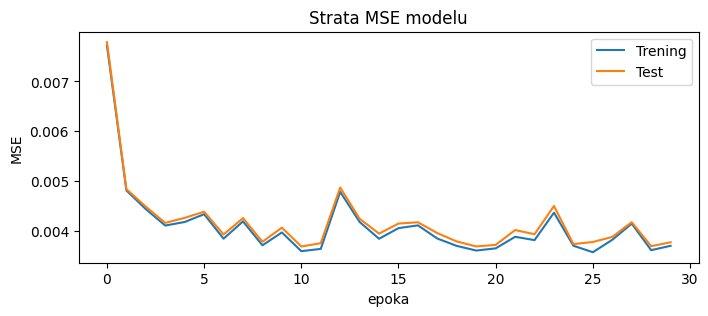

In [ ]:
plt.figure(figsize=(8,3))
plt.plot(hist_tr, label='Trening')
plt.plot(hist, label='Test')
plt.title('Strata MSE modelu'); plt.xlabel('epoka'); plt.ylabel('MSE')
plt.legend(); plt.show()

## 7. Predykcja vs rzeczywistość

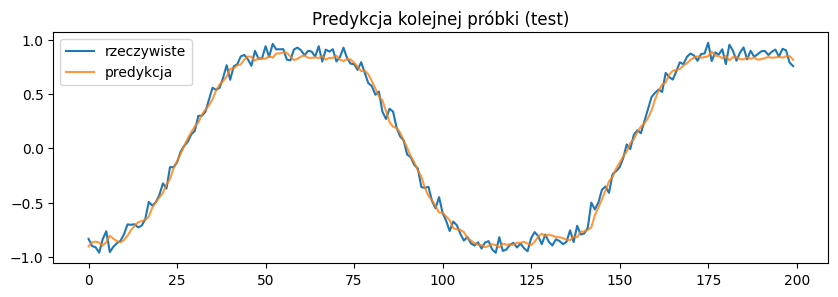

In [ ]:
model.eval()
with torch.no_grad():
    pred = model(Xte).cpu().numpy().ravel()
prawdziwe = Yte.cpu().numpy().ravel()

plt.figure(figsize=(10,3))
plt.plot(prawdziwe[:200], label='rzeczywiste')
plt.plot(pred[:200], label='predykcja', alpha=0.8)
plt.legend(); plt.title('Predykcja kolejnej próbki (test)'); plt.show()

## 8. Eksperyment: typ komórki oraz liczba jednostek

Porównanie SimpleRNN/LSTM/GRU i wpływu rozmiaru stanu ukrytego.

In [ ]:
print('Typ komórki (hidden=32):')
for typ in ['RNN','LSTM','GRU']:
    h_test, h_train = trenuj(ModelRNN(hidden=32, typ=typ), Xtr, Ytr, Xte, Yte, epoki=20)
    print(f'  {typ:5s} test MSE = {h_test[-1]:.4f}')

print('Liczba jednostek (GRU):')
for hs in [8, 16, 32]:
    h_test, h_train = trenuj(ModelRNN(hidden=hs, typ='GRU'), Xtr, Ytr, Xte, Yte, epoki=20)
    print(f'  hidden={hs:3d} test MSE = {h_test[-1]:.4f}')

Typ komórki (hidden=32):
  RNN   test MSE = 0.0039
  LSTM  test MSE = 0.0034
  GRU   test MSE = 0.0038
Liczba jednostek (GRU):
  hidden=  8 test MSE = 0.0036
  hidden= 16 test MSE = 0.0035
  hidden= 32 test MSE = 0.0033


## Eksperymenty do sprawozdania

In [22]:
import time
import pandas as pd
from IPython.display import display

def eksperymenty(seria, okno, hidden, typ, epoki=20, lr=1e-2, batch=64):
    X, Y = zrob_okna(seria, okno)
    n_tr = int(0.8*len(X))
    Xtr = torch.tensor(X[:n_tr]).to(DEVICE); Ytr = torch.tensor(Y[:n_tr]).to(DEVICE)
    Xte = torch.tensor(X[n_tr:]).to(DEVICE); Yte = torch.tensor(Y[n_tr:]).to(DEVICE)

    wyniki, czasy, historie_test = [], [], []
    liczba_param = 0

    for seed in [0, 1, 2]:
        torch.manual_seed(seed)
        model = ModelRNN(hidden=hidden, typ=typ)
        if seed == 0:
            liczba_param = sum(p.numel() for p in model.parameters())

        t0 = time.perf_counter()
        h, h_tr = trenuj(model, Xtr, Ytr, Xte, Yte, epoki=epoki, lr=lr, batch=batch)
        czas = time.perf_counter() - t0

        czasy.append(czas)
        wyniki.append(np.mean(h[-5:]))
        historie_test.append(h)

        # model z ostatniego ziarna dla późniejszych wykresów
        ostatni_model = model
        ostatnie_Xte, ostatnie_Yte = Xte, Yte
        ostatnie_htr = h_tr

    return {
        'konfiguracja': f"{typ}, okno={okno}, h={hidden}",
        'parametry': liczba_param,
        'mse_mean': np.mean(wyniki),
        'mse_std': np.std(wyniki),
        'czas_mean': np.mean(czasy),
        'hist_test_mean': np.mean(historie_test, axis=0),
        'mse_heurystyki': mse_heurystyki,
        'model': ostatni_model,
        'Xte': ostatnie_Xte, 'Yte': ostatnie_Yte,
        'h_tr': ostatnie_htr, 'h_te': historie_test[-1]
    }

def wyswietl_tabele(wyniki_lista):
    df = pd.DataFrame([{
        'Konfiguracja': w['konfiguracja'],
        'Liczba parametrów': w['parametry'],
        'Test MSE (śr ± odch)': f"{w['mse_mean']:.5f} ± {w['mse_std']:.5f}",
        'Czas treningu (s)': f"{w['czas_mean']:.2f}"
    } for w in wyniki_lista])

    print(f"Baza odniesienia - mse_heurystyki (ostatnia próbka): {wyniki_lista[0]['mse_heurystyki']:.5f}")
    display(df)

def rysuj_krzywe_eksperymentu(wyniki_lista, tytul):
    plt.figure(figsize=(10, 4))
    for w in wyniki_lista:
        plt.plot(w['hist_test_mean'], label=w['konfiguracja'])
    plt.title(tytul)
    plt.xlabel('Epoka')
    plt.ylabel('Test MSE (średnia z 3 uruchomień)')
    plt.legend()
    plt.grid(True)
    plt.show()

H: Zwiększenie hidden z 8 do 64 początkowo wyraźnie obniży błąd MSE, jednak dla najwyższej wartości (64) zysk będzie malał, a czas treningu znacząco wzrośnie.
Eksperyment A: Wpływ liczby jednostek (GRU, OKNO=30)
Baza odniesienia - mse_heurystyki (ostatnia próbka): 0.00631


,Konfiguracja,Liczba parametrów,Test MSE (śr ± odch),Czas treningu (s)
0,"GRU, okno=30, h=8",273,0.00380 ± 0.00004,5.85
1,"GRU, okno=30, h=16",929,0.00374 ± 0.00002,5.71
2,"GRU, okno=30, h=32",3393,0.00376 ± 0.00001,7.05
3,"GRU, okno=30, h=64",12929,0.00375 ± 0.00008,9.98


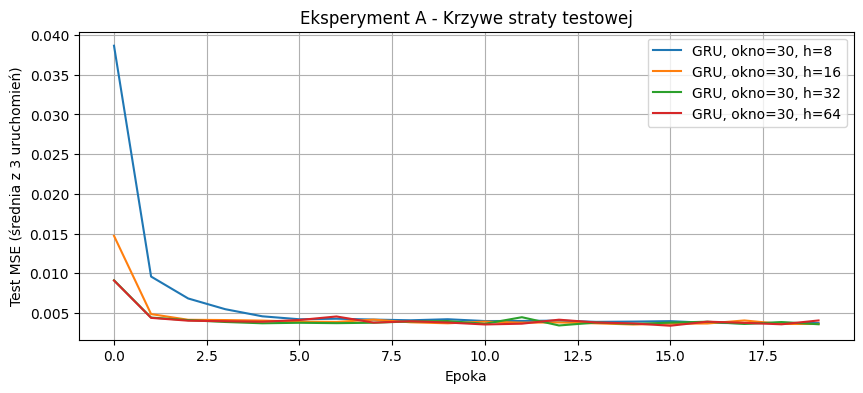

In [23]:
print('H: Zwiększenie hidden z 8 do 64 początkowo wyraźnie obniży błąd MSE, jednak dla najwyższej wartości (64) zysk będzie malał, a czas treningu znacząco wzrośnie.')
print('Eksperyment A: Wpływ liczby jednostek (GRU, OKNO=30)')
wyniki_A = []
for h in [8, 16, 32, 64]:
    res = eksperymenty(seria, okno=30, hidden=h, typ='GRU')
    wyniki_A.append(res)

wyswietl_tabele(wyniki_A)
rysuj_krzywe_eksperymentu(wyniki_A, 'Eksperyment A - Krzywe straty testowej')

H: Zwiększenie okna z 10 do 30 poprawi prognozę.
Eksperyment B: (GRU, hidden=32, OKNO zmienne)
Baza odniesienia - mse_heurystyki (ostatnia próbka): 0.00631


,Konfiguracja,Liczba parametrów,Test MSE (śr ± odch),Czas treningu (s)
0,"GRU, okno=10, h=32",3393,0.00414 ± 0.00019,2.66
1,"GRU, okno=30, h=32",3393,0.00376 ± 0.00001,6.71
2,"GRU, okno=60, h=32",3393,0.00343 ± 0.00021,12.88
3,"GRU, okno=120, h=32",3393,0.00344 ± 0.00019,24.07


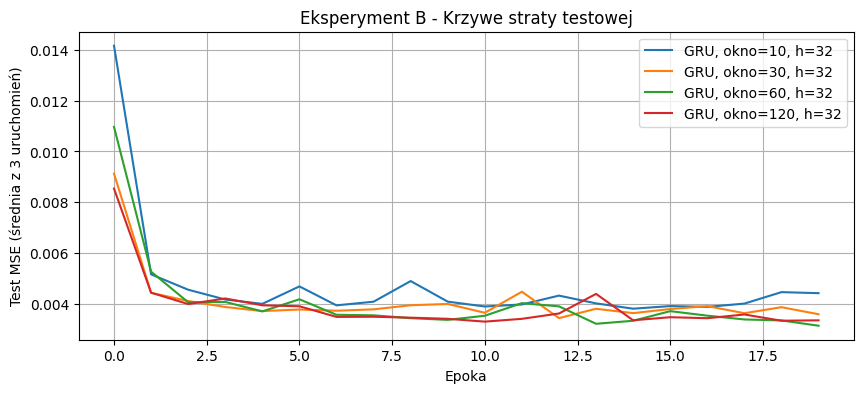

In [24]:
print('H: Zwiększenie okna z 10 do 30 poprawi prognozę.')
print('Eksperyment B: (GRU, hidden=32, OKNO zmienne)')
wyniki_B = []
for o in [10, 30, 60, 120]:
    res = eksperymenty(seria, okno=o, hidden=32, typ='GRU')
    wyniki_B.append(res)

wyswietl_tabele(wyniki_B)
rysuj_krzywe_eksperymentu(wyniki_B, 'Eksperyment B - Krzywe straty testowej')

H: Przy długim oknie (120) GRU i LSTM osiągną znacznie lepsze wyniki niż RNN.
Eksperyment C (hidden=32, typ i OKNO zmienne)
Baza odniesienia - mse_heurystyki (ostatnia próbka): 0.00631


,Konfiguracja,Liczba parametrów,Test MSE (śr ± odch),Czas treningu (s)
0,"RNN, okno=10, h=32",1153,0.00417 ± 0.00025,1.63
1,"LSTM, okno=10, h=32",4513,0.00415 ± 0.00011,2.14
2,"GRU, okno=10, h=32",3393,0.00414 ± 0.00019,2.91
3,"RNN, okno=120, h=32",1153,0.00400 ± 0.00001,9.05
4,"LSTM, okno=120, h=32",4513,0.00375 ± 0.00013,15.09
5,"GRU, okno=120, h=32",3393,0.00344 ± 0.00019,26.29


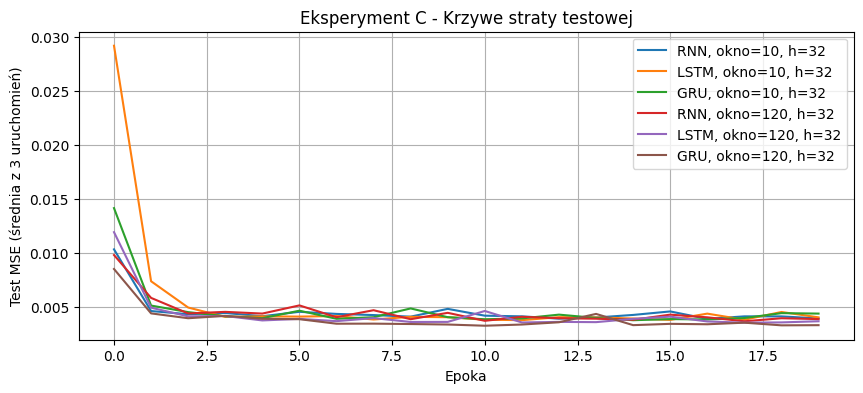

In [25]:
print('H: Przy długim oknie (120) GRU i LSTM osiągną znacznie lepsze wyniki niż RNN.')
print('Eksperyment C (hidden=32, typ i OKNO zmienne)')
wyniki_C = []
for o in [10, 120]:
    for t in ['RNN', 'LSTM', 'GRU']:
        res = eksperymenty(seria, okno=o, hidden=32, typ=t)
        wyniki_C.append(res)

wyswietl_tabele(wyniki_C)
rysuj_krzywe_eksperymentu(wyniki_C, 'Eksperyment C - Krzywe straty testowej')


Najlepsza znaleziona konfiguracja to: GRU, okno=60, h=32 (MSE: 0.00343)


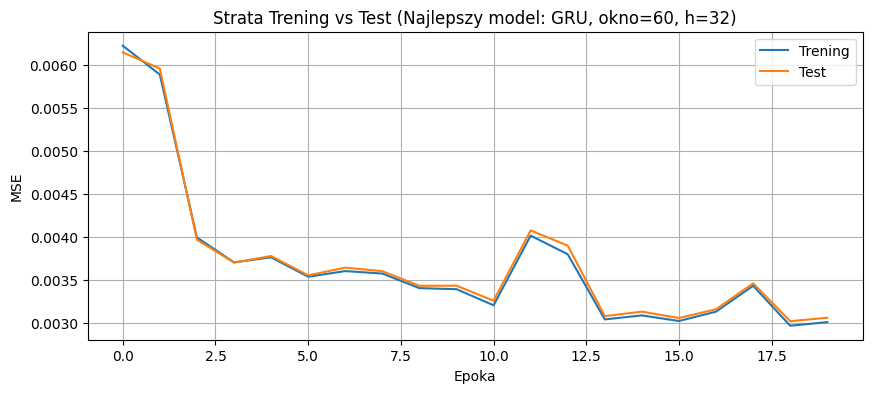

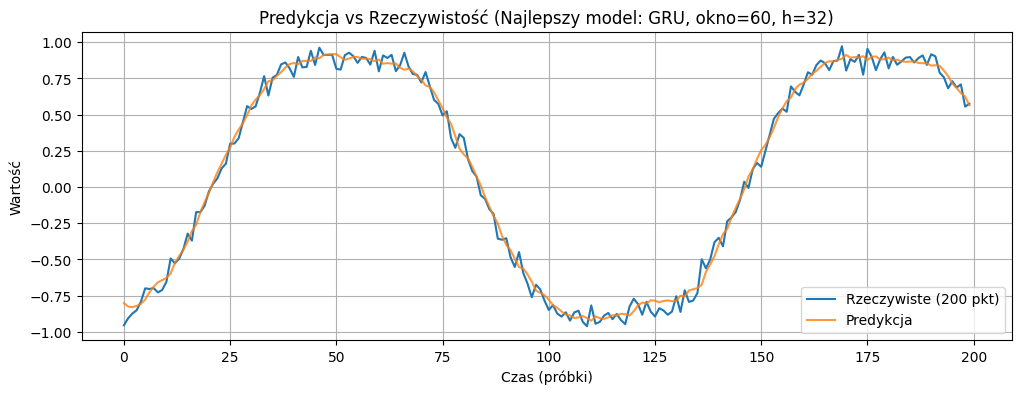

In [26]:
wszystkie_wyniki = wyniki_A + wyniki_B + wyniki_C
najlepszy_wynik = min(wszystkie_wyniki, key=lambda x: x['mse_mean'])

print(f"\nNajlepsza znaleziona konfiguracja to: {najlepszy_wynik['konfiguracja']} (MSE: {najlepszy_wynik['mse_mean']:.5f})")

model_best = najlepszy_wynik['model']
Xte_best = najlepszy_wynik['Xte']
Yte_best = najlepszy_wynik['Yte']

# krzywe straty treningowej i testowej
plt.figure(figsize=(10, 4))
plt.plot(najlepszy_wynik['h_tr'], label='Trening')
plt.plot(najlepszy_wynik['h_te'], label='Test')
plt.title(f"Strata Trening vs Test (Najlepszy model: {najlepszy_wynik['konfiguracja']})")
plt.xlabel('Epoka')
plt.ylabel('MSE')
plt.legend()
plt.grid(True)
plt.show()

# predykcja na tle rzeczywistego przebiegu
model_best.eval()
with torch.no_grad():
    pred = model_best(Xte_best).cpu().numpy().ravel()
prawdziwe = Yte_best.cpu().numpy().ravel()

plt.figure(figsize=(12, 4))
plt.plot(prawdziwe[:200], label='Rzeczywiste (200 pkt)')
plt.plot(pred[:200], label='Predykcja', alpha=0.8)
plt.title(f"Predykcja vs Rzeczywistość (Najlepszy model: {najlepszy_wynik['konfiguracja']})")
plt.xlabel('Czas (próbki)')
plt.ylabel('Wartość')
plt.legend()
plt.grid(True)
plt.show()